# Studi Kasus: Analisis Sentimen & Pra-Pemrosesan Teks Tinjauan Produk E-Commerce (Bahasa Indonesia)

# Install & Import Library

In [6]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [2]:
!pip install sastrawi spacy
!python -m spacy download en_core_web_sm

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# NLTK
import nltk
nltk.download('punkt')
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Sastrawi (Stemming Bahasa Indonesia)
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# spaCy
import spacy

# Sklearn (TF-IDF & PCA)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA

print("✅ Semua pustaka berhasil di-import!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 75.5 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✅ Semua pustaka berhasil di-import!


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# Pembuatan Dataset Random & Kamus Normalisasi

In [3]:
# Dataset contoh ulasan produk (mentah & kotor)
data_ulasan = [
    "Barang bagus bgt!! Pengiriman super cepattt.. Seller ramah bgt https://tokopedia.com/xyz @tokoonline_id #recommended",
    "Jelek parah, barang rusak pas sampe!! Kecewa berat sma pelayanannya 😡👎. Bintang 1 deh.",
    "Kualitas produk sangat baik, original dan fungsi berjalan lancar. Makasih seller!",
    "Lama bgt pengirimannya, respon penjual jg lambat bgt. Tolong ditingkatkan lg kualitasnya."
]

df = pd.DataFrame({'ulasan_mentah': data_ulasan})

# Kamus Singkatan / Kata Gaul (Normalisasi)
kamus_gaul = {
    "bgt": "banget",
    "cepattt": "cepat",
    "sma": "sama",
    "jg": "juga",
    "lg": "lagi",
    "makasih": "terima kasih"
}

print("Dataset Mentah:")
display(df)

Dataset Mentah:


,ulasan_mentah
0,Barang bagus bgt!! Pengiriman super cepattt.. ...
1,"Jelek parah, barang rusak pas sampe!! Kecewa b..."
2,"Kualitas produk sangat baik, original dan fung..."
3,"Lama bgt pengirimannya, respon penjual jg lamb..."


# Pembersihan Teks Dasar & Regex (Basic Processing)

In [4]:
def clean_text(text):
    # 1. Case Folding (Ubah ke huruf kecil)
    text = text.lower()
    # 2. Hapus URL
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    # 3. Hapus Mention (@username) dan Hashtag (#tag)
    text = re.sub(r'@\w+|#\w+', '', text)
    # 4. Hapus Angka dan Tanda Baca / Karakter Khusus / Emoji
    text = re.sub(r'[^a-z\s]', '', text)
    # 5. Hapus spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['step1_clean'] = df['ulasan_mentah'].apply(clean_text)

print("Hasil Step 1 (Cleaning Regex & Case Folding):")
for idx, text in enumerate(df['step1_clean']):
    print(f"{idx+1}. {text}")

Hasil Step 1 (Cleaning Regex & Case Folding):
1. barang bagus bgt pengiriman super cepattt seller ramah bgt
2. jelek parah barang rusak pas sampe kecewa berat sma pelayanannya bintang deh
3. kualitas produk sangat baik original dan fungsi berjalan lancar makasih seller
4. lama bgt pengirimannya respon penjual jg lambat bgt tolong ditingkatkan lg kualitasnya


# Tokenisasi & Normalisasi Kata (Kamus Gaul)

In [7]:
def normalisasi_kata(text, kamus):
    tokens = word_tokenize(text) # Tokenisasi menggunakan NLTK
    tokens_normalized = [kamus.get(word, word) for word in tokens]
    return " ".join(tokens_normalized)

df['step2_normalized'] = df['step1_clean'].apply(lambda x: normalisasi_kata(x, kamus_gaul))

print("Hasil Step 2 (Tokenisasi & Normalisasi Kata Gaul):")
for idx, text in enumerate(df['step2_normalized']):
    print(f"{idx+1}. {text}")

Hasil Step 2 (Tokenisasi & Normalisasi Kata Gaul):
1. barang bagus banget pengiriman super cepat seller ramah banget
2. jelek parah barang rusak pas sampe kecewa berat sama pelayanannya bintang deh
3. kualitas produk sangat baik original dan fungsi berjalan lancar terima kasih seller
4. lama banget pengirimannya respon penjual juga lambat banget tolong ditingkatkan lagi kualitasnya


# Stopwords Removal & Stemming (Sastrawi)

In [8]:
# Inisialisasi Sastrawi
stop_factory = StopWordRemoverFactory()
stopword_remover = stop_factory.create_stop_word_remover()

stem_factory = StemmerFactory()
stemmer = stem_factory.create_stemmer()

def remove_stopwords_and_stem(text):
    # Stopword Removal
    text_less_stopwords = stopword_remover.remove(text)
    # Stemming
    text_stemmed = stemmer.stem(text_less_stopwords)
    return text_stemmed

df['step3_stemmed'] = df['step2_normalized'].apply(remove_stopwords_and_stem)

print("Hasil Step 3 (Stopwords & Stemming Sastrawi):")
for idx, text in enumerate(df['step3_stemmed']):
    print(f"{idx+1}. {text}")

Hasil Step 3 (Stopwords & Stemming Sastrawi):
1. barang bagus banget kirim super cepat seller ramah banget
2. jelek parah barang rusak pas sampe kecewa berat sama layan bintang deh
3. kualitas produk sangat baik original fungsi jalan lancar terima kasih seller
4. lama banget kirim respon jual lambat banget tingkat kualitas


# Analisis POS Tagging & NER dengan spaCy

In [9]:
# Memuat model spaCy (English / Multilingual dasar)
nlp = spacy.load("en_core_web_sm")

contoh_kalimat = df['step2_normalized'].iloc[2] # "kualitas produk sangat baik original dan fungsi berjalan lancar terima kasih seller"
doc = nlp(contoh_kalimat)

print(f"Kalimat: '{contoh_kalimat}'\n")
print("--- POS Tagging (spaCy) ---")
for token in doc:
    print(f"{token.text:<15} | POS: {token.pos_:<10} | Tag: {token.tag_}")

Kalimat: 'kualitas produk sangat baik original dan fungsi berjalan lancar terima kasih seller'

--- POS Tagging (spaCy) ---
kualitas        | POS: NOUN       | Tag: NNS
produk          | POS: PROPN      | Tag: NNP
sangat          | POS: PROPN      | Tag: NNP
baik            | POS: VERB       | Tag: VBP
original        | POS: ADJ        | Tag: JJ
dan             | POS: PROPN      | Tag: NNP
fungsi          | POS: PROPN      | Tag: NNP
berjalan        | POS: PROPN      | Tag: NNP
lancar          | POS: PROPN      | Tag: NNP
terima          | POS: PROPN      | Tag: NNP
kasih           | POS: PROPN      | Tag: NNP
seller          | POS: NOUN       | Tag: NN


# Analisis POS Tagging & NER dengan spaCy

Matriks TF-IDF (Ukuran: (4, 34) ):


,bagus,baik,banget,barang,berat,bintang,cepat,deh,fungsi,jalan,...,ramah,respon,rusak,sama,sampe,sangat,seller,super,terima,tingkat
0,0.34604,0.000000,0.545645,0.272822,0.000000,0.000000,0.34604,0.000000,0.000000,0.000000,...,0.34604,0.000000,0.000000,0.000000,0.000000,0.000000,0.272822,0.34604,0.000000,0.000000
1,0.00000,0.000000,0.000000,0.231270,0.293337,0.293337,0.00000,0.293337,0.000000,0.000000,...,0.00000,0.000000,0.293337,0.293337,0.293337,0.000000,0.000000,0.00000,0.000000,0.000000
2,0.00000,0.312451,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.312451,0.312451,...,0.00000,0.000000,0.000000,0.000000,0.000000,0.312451,0.246340,0.00000,0.312451,0.000000
3,0.00000,0.000000,0.533687,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,...,0.00000,0.338457,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.338457


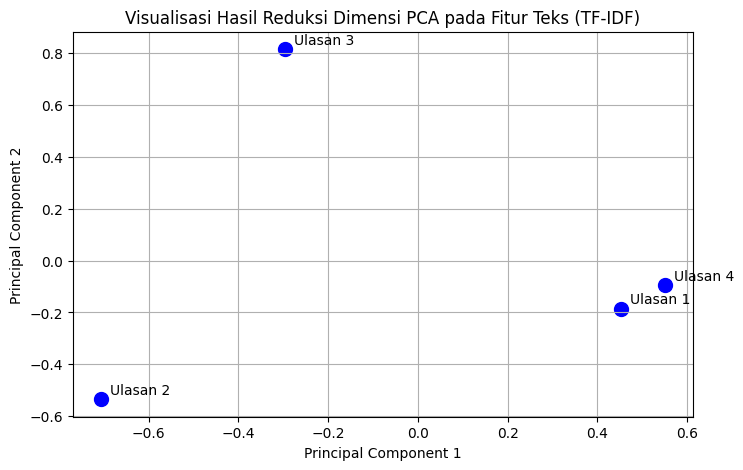

In [10]:
# 1. TF-IDF Vectorizer
vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(df['step3_stemmed'])

df_tfidf = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=vectorizer.get_feature_names_out()
)

print("Matriks TF-IDF (Ukuran:", tfidf_matrix.shape, "):")
display(df_tfidf.head())

# 2. Reduksi Dimensi dengan PCA (menjadi 2 Komponen)
pca = PCA(n_components=2)
pca_result = pca.fit_transform(tfidf_matrix.toarray())

df['pca_x'] = pca_result[:, 0]
df['pca_y'] = pca_result[:, 1]

# Visualisasi PCA
plt.figure(figsize=(8, 5))
plt.scatter(df['pca_x'], df['pca_y'], color='blue', s=100)

for i, txt in enumerate(df.index):
    plt.annotate(f"Ulasan {i+1}", (df['pca_x'].iloc[i]+0.02, df['pca_y'].iloc[i]+0.02))

plt.title("Visualisasi Hasil Reduksi Dimensi PCA pada Fitur Teks (TF-IDF)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()